# 🏛️ Étape 3 — Schéma physique et chargement du Data Warehouse
**Livrables couverts :** L05 (modèle physique) · L06 (ETL — étape *Load*) · BF06, BF07, BF09
**Entrée :** `transform_out/dw_tables/` (22 tables avec clés de substitution, issues de l'étape 2) · **Sortie :** `dw_pubmed.db` (SGBD **SQLite**), `load_out/` (scripts SQL, journal de chargement)

---
## 🎯 Principes
1. **Le schéma impose les règles** : clés primaires, clés étrangères (activées), `UNIQUE` sur les clés métier, `CHECK` sur les domaines (booléens 0/1, `nb_publications = 1`…). Une donnée incohérente est **refusée à l'insertion**.
2. **Chargement idempotent** : toutes les tables sont vidées puis rechargées dans **une seule transaction** ; relancer le notebook ne crée aucun doublon (le cahier des charges l'exige, §7.3). En cas d'erreur : annulation complète (*rollback*).
3. **Ordre de chargement = ordre des dépendances** : `pays_dim` → dimensions qui en dépendent → autres dimensions → `article_dim` → tables de liaison → `article_fact`.
4. **Contrôles après chargement** (BF09) : volumes source ↔ DW, intégrité référentielle, cohérence des mesures de la table de faits avec les tables de liaison, absence de double comptage.
5. **Journal** : chaque chargement est tracé dans la table `etl_log`.

## ⚙️ Choix du SGBD
**SQLite** (fichier unique, aucune installation) : c'est le SGBD déjà utilisé pour le fichier `dw_pubmed.db` du projet, et Power BI le lit via un connecteur ODBC. Le DDL utilise du SQL standard (clés, `REFERENCES`, `CHECK`) et se porte sur **PostgreSQL** en remplaçant seulement `INTEGER PRIMARY KEY` par `INTEGER PRIMARY KEY` / `BIGINT` et en retirant les `PRAGMA`.

In [3]:
import sqlite3, time, json, re
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 70)
C = {"main": "#1F4E79", "accent": "#E07B39", "ok": "#2E8B57", "warn": "#E0A030", "bad": "#C0392B", "grey": "#8895A7"}
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})

PARAMS = dict(DB_PATH="dw_pubmed.db",      # fichier du Data Warehouse
              REBUILD=True)                # True : le fichier est recréé à zéro (schéma neuf) ; False : schéma conservé, données rechargées
SRC = next((p for p in [Path("transform_out/dw_tables"), Path("data/transform_out/dw_tables")] if p.exists()), None)
assert SRC is not None, "Lance d'abord le notebook de l'étape 2 (dossier transform_out/dw_tables introuvable)."
OUT = SRC.parent.parent / "load_out"; OUT.mkdir(exist_ok=True)
DB = SRC.parent.parent / PARAMS["DB_PATH"]
print("Source :", SRC.resolve()); print("Data Warehouse :", DB.resolve())

Source : C:\IDSD\3eme_annee_IDSD\archi moderne\pubmed_project\transform_out\dw_tables
Data Warehouse : C:\IDSD\3eme_annee_IDSD\archi moderne\pubmed_project\dw_pubmed.db


---
# L1 — Schéma physique (DDL)
Le modèle est un **flocon** : 1 table de faits `article_fact` (une ligne = une publication), des **dimensions**, une **sous-dimension** (`pays_dim`, référencée par `revue_dim` et `institution_dim`) et 8 **tables de liaison** `article_<x>_bridge` pour les relations N-N.

```
                       pays_dim ◄──── revue_dim ◄─────────┐
                          ▲  ▲                            │
 temps_dim ◄──(2 rôles)───┼──┼─── article_fact ──► statut_dim, categorie_dim, langue_dim, pays_dim
                          │  │          │
          institution_dim─┘  │          └──► article_dim ◄── 8 tables de liaison ──► auteur_dim, mesh_dim, motcle_dim,
                             │                                                       type_publication_dim, langue_dim, pays_dim,
                             └─ (pays des institutions)                              substance_dim, institution_dim (+ auteur_dim)
```

In [4]:
DDL = """
CREATE TABLE IF NOT EXISTS pays_dim (
    pays_key INTEGER PRIMARY KEY, pays TEXT NOT NULL UNIQUE);
CREATE TABLE IF NOT EXISTS statut_dim (
    statut_key INTEGER PRIMARY KEY, statut_citation TEXT NOT NULL UNIQUE);
CREATE TABLE IF NOT EXISTS categorie_dim (
    categorie_key INTEGER PRIMARY KEY, categorie TEXT NOT NULL UNIQUE);
CREATE TABLE IF NOT EXISTS langue_dim (
    langue_key INTEGER PRIMARY KEY, code_langue TEXT NOT NULL UNIQUE, libelle TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS type_publication_dim (
    type_key INTEGER PRIMARY KEY, ui_type TEXT NOT NULL UNIQUE, libelle TEXT NOT NULL);
CREATE TABLE IF NOT EXISTS mesh_dim (
    mesh_key INTEGER PRIMARY KEY, ui_mesh TEXT NOT NULL UNIQUE, descripteur TEXT NOT NULL,
    est_geographique INTEGER NOT NULL CHECK (est_geographique IN (0, 1)));
CREATE TABLE IF NOT EXISTS motcle_dim (
    motcle_key INTEGER PRIMARY KEY, cle_motcle TEXT NOT NULL UNIQUE, libelle TEXT NOT NULL, nb_publications INTEGER NOT NULL);
CREATE TABLE IF NOT EXISTS substance_dim (
    substance_key INTEGER PRIMARY KEY, ui_substance TEXT NOT NULL UNIQUE, substance TEXT NOT NULL, registre TEXT, nb_publications INTEGER NOT NULL);
CREATE TABLE IF NOT EXISTS temps_dim (
    temps_key INTEGER PRIMARY KEY,                       -- AAAAMM00 (mois), AAAA0000 (année seule), AAAAMMJJ (jour), 0 = inconnu
    annee INTEGER, mois INTEGER CHECK (mois BETWEEN 1 AND 12), jour INTEGER,
    niveau TEXT NOT NULL CHECK (niveau IN ('Jour', 'Mois', 'Année', 'Inconnu')), libelle_mois TEXT, trimestre INTEGER);
CREATE TABLE IF NOT EXISTS auteur_dim (
    auteur_key INTEGER PRIMARY KEY, cle_auteur TEXT NOT NULL UNIQUE,
    type_auteur TEXT NOT NULL CHECK (type_auteur IN ('Individuel', 'Collectif')),
    nom TEXT NOT NULL, prenom_frequent TEXT, initiales TEXT, orcid TEXT, nb_prenoms_distincts INTEGER, nb_publications INTEGER NOT NULL);
CREATE TABLE IF NOT EXISTS revue_dim (
    revue_key INTEGER PRIMARY KEY, nlm_id TEXT NOT NULL UNIQUE, titre TEXT NOT NULL, abrev TEXT, issn TEXT, issn_liaison TEXT,
    pays_key INTEGER NOT NULL REFERENCES pays_dim (pays_key));                      -- sous-dimension : pays de l'éditeur
CREATE TABLE IF NOT EXISTS institution_dim (
    institution_key INTEGER PRIMARY KEY, cle_institution TEXT NOT NULL UNIQUE, libelle TEXT NOT NULL,
    pays_key INTEGER NOT NULL REFERENCES pays_dim (pays_key), nb_publications INTEGER NOT NULL);   -- sous-dimension : pays de l'institution
CREATE TABLE IF NOT EXISTS article_dim (
    article_key INTEGER PRIMARY KEY, pmid TEXT NOT NULL UNIQUE, titre TEXT NOT NULL,
    titre_traduit INTEGER NOT NULL CHECK (titre_traduit IN (0, 1)), doi TEXT, resume_court TEXT,
    a_resume INTEGER NOT NULL CHECK (a_resume IN (0, 1)), est_indexe_mesh INTEGER NOT NULL CHECK (est_indexe_mesh IN (0, 1)),
    source_date_pub TEXT NOT NULL, source_fichier TEXT NOT NULL, niveau_reparation TEXT NOT NULL);

-- Tables de liaison (relations N-N de l'article)
CREATE TABLE IF NOT EXISTS article_auteur_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), auteur_key INTEGER NOT NULL REFERENCES auteur_dim (auteur_key),
    rang INTEGER NOT NULL CHECK (rang >= 1), est_premier INTEGER NOT NULL CHECK (est_premier IN (0, 1)), est_dernier INTEGER NOT NULL CHECK (est_dernier IN (0, 1)),
    PRIMARY KEY (article_key, auteur_key));
CREATE TABLE IF NOT EXISTS article_mesh_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), mesh_key INTEGER NOT NULL REFERENCES mesh_dim (mesh_key),
    majeur INTEGER NOT NULL CHECK (majeur IN (0, 1)), PRIMARY KEY (article_key, mesh_key));
CREATE TABLE IF NOT EXISTS article_motcle_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), motcle_key INTEGER NOT NULL REFERENCES motcle_dim (motcle_key),
    PRIMARY KEY (article_key, motcle_key));
CREATE TABLE IF NOT EXISTS article_type_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), type_key INTEGER NOT NULL REFERENCES type_publication_dim (type_key),
    PRIMARY KEY (article_key, type_key));
CREATE TABLE IF NOT EXISTS article_langue_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), langue_key INTEGER NOT NULL REFERENCES langue_dim (langue_key),
    est_principale INTEGER NOT NULL CHECK (est_principale IN (0, 1)), PRIMARY KEY (article_key, langue_key));
CREATE TABLE IF NOT EXISTS article_pays_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), pays_key INTEGER NOT NULL REFERENCES pays_dim (pays_key),
    PRIMARY KEY (article_key, pays_key));
CREATE TABLE IF NOT EXISTS article_substance_bridge (
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), substance_key INTEGER NOT NULL REFERENCES substance_dim (substance_key),
    PRIMARY KEY (article_key, substance_key));
CREATE TABLE IF NOT EXISTS article_institution_bridge (                          -- ternaire : une institution est rattachée à un couple (article, auteur)
    article_key INTEGER NOT NULL REFERENCES article_dim (article_key), auteur_key INTEGER NOT NULL REFERENCES auteur_dim (auteur_key),
    institution_key INTEGER NOT NULL REFERENCES institution_dim (institution_key), PRIMARY KEY (article_key, auteur_key, institution_key));

-- Table de faits : clés étrangères + mesures uniquement
CREATE TABLE IF NOT EXISTS article_fact (
    article_key INTEGER PRIMARY KEY REFERENCES article_dim (article_key),
    revue_key INTEGER NOT NULL REFERENCES revue_dim (revue_key),
    temps_pub_key INTEGER NOT NULL REFERENCES temps_dim (temps_key), temps_creation_key INTEGER NOT NULL REFERENCES temps_dim (temps_key),
    categorie_key INTEGER NOT NULL REFERENCES categorie_dim (categorie_key), statut_key INTEGER NOT NULL REFERENCES statut_dim (statut_key),
    langue_key INTEGER NOT NULL REFERENCES langue_dim (langue_key), pays_premier_auteur_key INTEGER NOT NULL REFERENCES pays_dim (pays_key),
    nb_publications INTEGER NOT NULL CHECK (nb_publications = 1),
    nb_auteurs INTEGER NOT NULL CHECK (nb_auteurs >= 0), nb_collectifs INTEGER NOT NULL CHECK (nb_collectifs >= 0),
    nb_mesh INTEGER NOT NULL CHECK (nb_mesh >= 0), nb_mesh_majeurs INTEGER NOT NULL CHECK (nb_mesh_majeurs >= 0),
    nb_mots_cles INTEGER NOT NULL CHECK (nb_mots_cles >= 0), nb_pays INTEGER NOT NULL CHECK (nb_pays >= 0),
    nb_substances INTEGER NOT NULL CHECK (nb_substances >= 0), nb_institutions INTEGER NOT NULL CHECK (nb_institutions >= 0),
    mots_titre INTEGER NOT NULL CHECK (mots_titre >= 0), mots_resume INTEGER NOT NULL CHECK (mots_resume >= 0));

-- Index sur les clés étrangères (jointures et agrégations)
CREATE INDEX IF NOT EXISTS ix_fact_revue ON article_fact (revue_key);
CREATE INDEX IF NOT EXISTS ix_fact_temps_pub ON article_fact (temps_pub_key);
CREATE INDEX IF NOT EXISTS ix_fact_temps_creation ON article_fact (temps_creation_key);
CREATE INDEX IF NOT EXISTS ix_fact_categorie ON article_fact (categorie_key);
CREATE INDEX IF NOT EXISTS ix_fact_pays_premier ON article_fact (pays_premier_auteur_key);
CREATE INDEX IF NOT EXISTS ix_auteur_bridge_auteur ON article_auteur_bridge (auteur_key);
CREATE INDEX IF NOT EXISTS ix_mesh_bridge_mesh ON article_mesh_bridge (mesh_key);
CREATE INDEX IF NOT EXISTS ix_motcle_bridge_motcle ON article_motcle_bridge (motcle_key);
CREATE INDEX IF NOT EXISTS ix_type_bridge_type ON article_type_bridge (type_key);
CREATE INDEX IF NOT EXISTS ix_pays_bridge_pays ON article_pays_bridge (pays_key);
CREATE INDEX IF NOT EXISTS ix_substance_bridge_substance ON article_substance_bridge (substance_key);
CREATE INDEX IF NOT EXISTS ix_institution_bridge_inst ON article_institution_bridge (institution_key);
CREATE INDEX IF NOT EXISTS ix_revue_pays ON revue_dim (pays_key);
CREATE INDEX IF NOT EXISTS ix_institution_pays ON institution_dim (pays_key);

-- Journal du chargement (BF09)
CREATE TABLE IF NOT EXISTS etl_log (
    run_id TEXT NOT NULL, table_name TEXT NOT NULL, lignes_source INTEGER NOT NULL, lignes_chargees INTEGER NOT NULL,
    duree_s REAL NOT NULL, statut TEXT NOT NULL, horodatage TEXT NOT NULL);
"""
# dépendances : une table n'est chargée qu'après celles qu'elle référence
ORDRE = ["pays_dim", "statut_dim", "categorie_dim", "langue_dim", "type_publication_dim", "mesh_dim", "motcle_dim", "substance_dim", "temps_dim", "auteur_dim",
         "revue_dim", "institution_dim", "article_dim",
         "article_auteur_bridge", "article_mesh_bridge", "article_motcle_bridge", "article_type_bridge", "article_langue_bridge", "article_pays_bridge", "article_substance_bridge", "article_institution_bridge",
         "article_fact"]
if PARAMS["REBUILD"] and DB.exists(): DB.unlink()
con = sqlite3.connect(DB); con.execute("PRAGMA foreign_keys = ON"); con.executescript(DDL)
(OUT / "schema_dw.sql").write_text(DDL, encoding="utf-8")
print(f"{len(ORDRE)} tables créées + etl_log · clés étrangères activées : {con.execute('PRAGMA foreign_keys').fetchone()[0] == 1}")
pd.DataFrame([(t, len(list(con.execute(f"PRAGMA table_info({t})"))), len(list(con.execute(f"PRAGMA foreign_key_list({t})")))) for t in ORDRE], columns=["table", "colonnes", "clés étrangères"]).set_index("table")

22 tables créées + etl_log · clés étrangères activées : True


,colonnes,clés étrangères
table,,
pays_dim,2,0
statut_dim,2,0
categorie_dim,2,0
langue_dim,3,0
type_publication_dim,3,0
mesh_dim,4,0
motcle_dim,4,0
substance_dim,5,0
temps_dim,7,0


---
# L2 — Chargement (idempotent, transactionnel)
Lecture des CSV **en texte** (`keep_default_na=False` : seule la chaîne vide devient `NULL`, pour ne pas perdre des valeurs réelles comme les initiales « NA »), conversion des types d'après le schéma, puis insertion dans l'ordre des dépendances. Les colonnes du CSV doivent être **exactement** celles de la table (sinon le chargement s'arrête).

In [5]:
def lire(table):
    """CSV -> liste de tuples typés d'après le schéma de la table (INTEGER -> int, TEXT -> str, vide -> None)."""
    info = list(con.execute(f"PRAGMA table_info({table})")); cols = [r[1] for r in info]; types = {r[1]: r[2] for r in info}
    df = pd.read_csv(SRC / f"{table}.csv", dtype=str, keep_default_na=False, na_values=[""])
    assert set(df.columns) == set(cols), f"{table} : colonnes CSV ≠ schéma ({set(df.columns) ^ set(cols)})"
    df = df[cols]
    for c in cols:
        if types[c] == "INTEGER": df[c] = pd.to_numeric(df[c].replace({"True": "1", "False": "0"}), errors="raise").astype("Int64")
    rows = [tuple(None if pd.isna(v) else (int(v) if types[c] == "INTEGER" else v) for c, v in zip(cols, r)) for r in df.itertuples(index=False, name=None)]
    return cols, rows

def charger():
    """Vide puis recharge les 22 tables dans UNE transaction (tout ou rien). Retourne le journal du chargement."""
    run_id, journal = datetime.now().strftime("%Y%m%d-%H%M%S-%f"), []
    try:
        con.execute("BEGIN")
        for t in reversed(ORDRE): con.execute(f"DELETE FROM {t}")                       # enfants d'abord
        for t in ORDRE:                                                                  # parents d'abord
            t0 = time.time(); cols, rows = lire(t)
            con.executemany(f"INSERT INTO {t} ({', '.join(cols)}) VALUES ({', '.join('?' * len(cols))})", rows)
            n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
            journal.append((run_id, t, len(rows), n, round(time.time() - t0, 3), "OK" if n == len(rows) else "ÉCART", datetime.now().isoformat(timespec="seconds")))
        con.executemany("INSERT INTO etl_log VALUES (?,?,?,?,?,?,?)", journal); con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK"); raise
    return pd.DataFrame(journal, columns=["run_id", "table_name", "lignes_source", "lignes_chargees", "duree_s", "statut", "horodatage"])

log1 = charger()
print(f"Chargement terminé : {log1.lignes_chargees.sum():,} lignes dans {len(log1)} tables en {log1.duree_s.sum():.1f} s · statuts : {log1.statut.value_counts().to_dict()}")
log1.drop(columns=["run_id", "horodatage"]).set_index("table_name")

Chargement terminé : 168,807 lignes dans 22 tables en 2.3 s · statuts : {'OK': 22}


,lignes_source,lignes_chargees,duree_s,statut
table_name,,,,
pays_dim,77,77,0.040,OK
statut_dim,6,6,0.011,OK
categorie_dim,8,8,0.011,OK
langue_dim,16,16,0.012,OK
type_publication_dim,36,36,0.010,OK
mesh_dim,3937,3937,0.041,OK
motcle_dim,6545,6545,0.066,OK
substance_dim,2594,2594,0.038,OK
temps_dim,608,608,0.026,OK


---
# L3 — Contrôles après chargement (BF09)
Chaque contrôle est un `assert` : si une règle est violée, le notebook **s'arrête**.

In [6]:
Q = lambda sql: con.execute(sql).fetchall()
res = []
def check(nom, cond, detail=""):
    res.append(dict(contrôle=nom, résultat="✅ OK" if cond else "❌ ÉCHEC", détail=detail)); assert cond, f"Contrôle en échec : {nom} {detail}"

# 1. Volumes : CSV (étape 2) ↔ base
for t in ORDRE:
    n_csv = sum(1 for _ in open(SRC / f"{t}.csv", encoding="utf-8")) - 1; n_db = Q(f"SELECT COUNT(*) FROM {t}")[0][0]
    check(f"Volumes {t} : CSV = base", n_csv == n_db, f"{n_db:,} lignes")
# 2. Intégrité structurelle
check("PRAGMA integrity_check = ok", Q("PRAGMA integrity_check")[0][0] == "ok")
check("PRAGMA foreign_key_check : aucune clé étrangère orpheline", Q("PRAGMA foreign_key_check") == [])
# 3. Table de faits : 1 ligne par article, nb_publications = 1
check("article_fact : exactement 1 ligne par article de article_dim", Q("SELECT COUNT(*) FROM article_dim a LEFT JOIN article_fact f USING (article_key) WHERE f.article_key IS NULL")[0][0] == 0
      and Q("SELECT COUNT(*) FROM article_fact")[0][0] == Q("SELECT COUNT(*) FROM article_dim")[0][0])
check("SUM(nb_publications) = nombre d'articles", Q("SELECT SUM(nb_publications) FROM article_fact")[0][0] == Q("SELECT COUNT(*) FROM article_dim")[0][0])
# 4. Cohérence mesures de la fait ↔ tables de liaison (un écart = un double comptage ou une perte)
def ecarts(mesure, sql_compte):
    return Q(f"SELECT COUNT(*) FROM article_fact f LEFT JOIN ({sql_compte}) c USING (article_key) WHERE f.{mesure} <> COALESCE(c.n, 0)")[0][0]
for mesure, sql in [("nb_auteurs", "SELECT article_key, COUNT(*) n FROM article_auteur_bridge GROUP BY article_key"),
                    ("nb_collectifs", "SELECT b.article_key, COUNT(*) n FROM article_auteur_bridge b JOIN auteur_dim a USING (auteur_key) WHERE a.type_auteur = 'Collectif' GROUP BY b.article_key"),
                    ("nb_mesh", "SELECT article_key, COUNT(*) n FROM article_mesh_bridge GROUP BY article_key"),
                    ("nb_mesh_majeurs", "SELECT article_key, COUNT(*) n FROM article_mesh_bridge WHERE majeur = 1 GROUP BY article_key"),
                    ("nb_mots_cles", "SELECT article_key, COUNT(*) n FROM article_motcle_bridge GROUP BY article_key"),
                    ("nb_pays", "SELECT article_key, COUNT(*) n FROM article_pays_bridge GROUP BY article_key"),
                    ("nb_substances", "SELECT article_key, COUNT(*) n FROM article_substance_bridge GROUP BY article_key"),
                    ("nb_institutions", "SELECT article_key, COUNT(DISTINCT institution_key) n FROM article_institution_bridge GROUP BY article_key")]:
    e = ecarts(mesure, sql); check(f"article_fact.{mesure} = comptage dans la table de liaison", e == 0, f"{e} articles en écart")
# 5. Règles métier
check("Une seule langue principale au plus par article", Q("SELECT COUNT(*) FROM (SELECT article_key FROM article_langue_bridge WHERE est_principale = 1 GROUP BY article_key HAVING COUNT(*) > 1)")[0][0] == 0)
check("Langue principale de la fait ∈ langues de l'article (ou 0)", Q("SELECT COUNT(*) FROM article_fact f WHERE f.langue_key <> 0 AND NOT EXISTS (SELECT 1 FROM article_langue_bridge b WHERE b.article_key = f.article_key AND b.langue_key = f.langue_key)")[0][0] == 0)
check("Un seul premier auteur par article", Q("SELECT COUNT(*) FROM (SELECT article_key FROM article_auteur_bridge WHERE est_premier = 1 GROUP BY article_key HAVING COUNT(*) > 1)")[0][0] == 0)
check("Membre « non renseigné » (clé 0) présent dans temps, pays, langue, statut", all(Q(f"SELECT COUNT(*) FROM {t} WHERE {k} = 0")[0][0] == 1 for t, k in [("temps_dim", "temps_key"), ("pays_dim", "pays_key"), ("langue_dim", "langue_key"), ("statut_dim", "statut_key")]))
# 6. Idempotence : un second chargement ne change rien
avant = {t: Q(f"SELECT COUNT(*) FROM {t}")[0][0] for t in ORDRE}; log2 = charger(); apres = {t: Q(f"SELECT COUNT(*) FROM {t}")[0][0] for t in ORDRE}
check("Idempotence : 2ᵉ chargement = mêmes volumes, aucun doublon", avant == apres and Q("PRAGMA foreign_key_check") == [], f"{sum(apres.values()):,} lignes")
pd.DataFrame(res)

,contrôle,résultat,détail
0,Volumes pays_dim : CSV = base,✅ OK,77 lignes
1,Volumes statut_dim : CSV = base,✅ OK,6 lignes
2,Volumes categorie_dim : CSV = base,✅ OK,8 lignes
3,Volumes langue_dim : CSV = base,✅ OK,16 lignes
4,Volumes type_publication_dim : CSV = base,✅ OK,36 lignes
5,Volumes mesh_dim : CSV = base,✅ OK,"3,937 lignes"
6,Volumes motcle_dim : CSV = base,✅ OK,"6,545 lignes"
7,Volumes substance_dim : CSV = base,✅ OK,"2,594 lignes"
8,Volumes temps_dim : CSV = base,✅ OK,608 lignes
9,Volumes auteur_dim : CSV = base,✅ OK,"20,464 lignes"


### Démonstration : pourquoi la table de faits est à 1 ligne par publication
Si l'on joignait naïvement la fait à la table de liaison des auteurs, chaque publication serait **répétée autant de fois qu'elle a d'auteurs**. Avec `COUNT(DISTINCT article_key)` le total est correct *pour les articles qui ont des auteurs* — mais les publications **sans auteur disparaissent** d'une jointure interne (le résultat est inférieur au vrai total). Seule la table de faits, qui compte 1 par publication, donne toujours le total exact.

In [7]:
naif = Q("SELECT COUNT(*) FROM article_fact f JOIN article_auteur_bridge b USING (article_key)")[0][0]
exact_distinct = Q("SELECT COUNT(DISTINCT f.article_key) FROM article_fact f JOIN article_auteur_bridge b USING (article_key)")[0][0]
exact_fait = Q("SELECT SUM(nb_publications) FROM article_fact")[0][0]
naif3 = Q("SELECT COUNT(*) FROM article_fact f JOIN article_auteur_bridge a USING (article_key) JOIN article_mesh_bridge m USING (article_key) JOIN article_motcle_bridge k USING (article_key)")[0][0]
pd.DataFrame({"méthode": ["Jointure naïve fait × auteurs (COUNT *)", "Jointure naïve fait × auteurs × MeSH × mots-clés (COUNT *)", "COUNT(DISTINCT article_key) après jointure", "SUM(nb_publications) dans la table de faits"],
              "résultat": [naif, naif3, exact_distinct, exact_fait]}).assign(facteur=lambda d: (d.résultat / exact_fait).round(1)).set_index("méthode")

,résultat,facteur
méthode,,
Jointure naïve fait × auteurs (COUNT *),29296,7.4
Jointure naïve fait × auteurs × MeSH × mots-clés (COUNT *),724572,182.6
COUNT(DISTINCT article_key) après jointure,3960,1.0
SUM(nb_publications) dans la table de faits,3967,1.0


---
# L4 — Vues analytiques (BF07)
Une vue par axe d'analyse du cahier des charges (§2.3). Elles **comptent des articles distincts** dès qu'elles passent par une table de liaison, pour éviter tout double comptage ; elles serviront directement de sources à Power BI (étape suivante : tableaux de bord).

In [8]:
VUES = """
DROP VIEW IF EXISTS v_publications_par_annee; DROP VIEW IF EXISTS v_publications_par_mois; DROP VIEW IF EXISTS v_publications_par_revue; DROP VIEW IF EXISTS v_publications_par_pays_revue;
DROP VIEW IF EXISTS v_auteurs_publications; DROP VIEW IF EXISTS v_nb_auteurs_par_annee; DROP VIEW IF EXISTS v_publications_par_institution; DROP VIEW IF EXISTS v_publications_par_pays_affiliation;
DROP VIEW IF EXISTS v_collaborations_institutions; DROP VIEW IF EXISTS v_collaborations_pays; DROP VIEW IF EXISTS v_themes_mesh; DROP VIEW IF EXISTS v_mots_cles; DROP VIEW IF EXISTS v_substances;
DROP VIEW IF EXISTS v_types_publication; DROP VIEW IF EXISTS v_categories_publication;

-- Axe 1 : évolution temporelle
CREATE VIEW v_publications_par_annee AS
SELECT t.annee, SUM(f.nb_publications) AS nb_publications FROM article_fact f JOIN temps_dim t ON t.temps_key = f.temps_pub_key WHERE t.annee IS NOT NULL GROUP BY t.annee;
CREATE VIEW v_publications_par_mois AS            -- niveau « Mois » uniquement (le mois est inconnu pour les publications au niveau « Année »)
SELECT t.annee, t.mois, t.libelle_mois, t.trimestre, SUM(f.nb_publications) AS nb_publications
FROM article_fact f JOIN temps_dim t ON t.temps_key = f.temps_pub_key WHERE t.niveau = 'Mois' GROUP BY t.annee, t.mois, t.libelle_mois, t.trimestre;
-- Axe 2 : revues
CREATE VIEW v_publications_par_revue AS
SELECT r.revue_key, r.nlm_id, r.titre AS revue, p.pays AS pays_editeur, SUM(f.nb_publications) AS nb_publications, ROUND(AVG(f.nb_auteurs), 2) AS nb_moyen_auteurs
FROM article_fact f JOIN revue_dim r USING (revue_key) JOIN pays_dim p ON p.pays_key = r.pays_key GROUP BY r.revue_key, r.nlm_id, r.titre, p.pays;
CREATE VIEW v_publications_par_pays_revue AS
SELECT p.pays AS pays_editeur, SUM(f.nb_publications) AS nb_publications, COUNT(DISTINCT r.revue_key) AS nb_revues
FROM article_fact f JOIN revue_dim r USING (revue_key) JOIN pays_dim p ON p.pays_key = r.pays_key GROUP BY p.pays;
-- Axe 3 : auteurs, affiliations, collaborations
CREATE VIEW v_auteurs_publications AS
SELECT a.auteur_key, a.nom, a.initiales, a.type_auteur, COUNT(DISTINCT b.article_key) AS nb_publications, SUM(b.est_premier) AS nb_fois_premier, SUM(b.est_dernier) AS nb_fois_dernier
FROM article_auteur_bridge b JOIN auteur_dim a USING (auteur_key) GROUP BY a.auteur_key, a.nom, a.initiales, a.type_auteur;
CREATE VIEW v_nb_auteurs_par_annee AS
SELECT t.annee, ROUND(AVG(f.nb_auteurs), 2) AS nb_moyen_auteurs, ROUND(AVG(f.nb_auteurs - f.nb_collectifs), 2) AS nb_moyen_auteurs_individuels, SUM(f.nb_publications) AS nb_publications
FROM article_fact f JOIN temps_dim t ON t.temps_key = f.temps_pub_key WHERE t.annee IS NOT NULL GROUP BY t.annee;
CREATE VIEW v_publications_par_institution AS
SELECT i.institution_key, i.libelle AS institution, p.pays, COUNT(DISTINCT b.article_key) AS nb_publications, COUNT(DISTINCT b.auteur_key) AS nb_auteurs
FROM article_institution_bridge b JOIN institution_dim i USING (institution_key) JOIN pays_dim p ON p.pays_key = i.pays_key GROUP BY i.institution_key, i.libelle, p.pays;
CREATE VIEW v_publications_par_pays_affiliation AS
SELECT p.pays, COUNT(DISTINCT b.article_key) AS nb_publications FROM article_pays_bridge b JOIN pays_dim p USING (pays_key) GROUP BY p.pays;
CREATE VIEW v_collaborations_institutions AS      -- paires d'institutions présentes dans une même publication
WITH ia AS (SELECT DISTINCT article_key, institution_key FROM article_institution_bridge)
SELECT i1.libelle AS institution_1, i2.libelle AS institution_2, COUNT(*) AS nb_publications_communes
FROM ia a JOIN ia b ON a.article_key = b.article_key AND a.institution_key < b.institution_key
JOIN institution_dim i1 ON i1.institution_key = a.institution_key JOIN institution_dim i2 ON i2.institution_key = b.institution_key GROUP BY a.institution_key, b.institution_key;
CREATE VIEW v_collaborations_pays AS              -- paires de pays présentes dans une même publication
SELECT p1.pays AS pays_1, p2.pays AS pays_2, COUNT(*) AS nb_publications_communes
FROM article_pays_bridge a JOIN article_pays_bridge b ON a.article_key = b.article_key AND a.pays_key < b.pays_key
JOIN pays_dim p1 ON p1.pays_key = a.pays_key JOIN pays_dim p2 ON p2.pays_key = b.pays_key WHERE a.pays_key <> 0 AND b.pays_key <> 0 GROUP BY a.pays_key, b.pays_key;
-- Axe 4 : thématiques
CREATE VIEW v_themes_mesh AS
SELECT m.mesh_key, m.descripteur, m.est_geographique, COUNT(DISTINCT b.article_key) AS nb_publications, SUM(b.majeur) AS nb_fois_majeur
FROM article_mesh_bridge b JOIN mesh_dim m USING (mesh_key) GROUP BY m.mesh_key, m.descripteur, m.est_geographique;
CREATE VIEW v_mots_cles AS
SELECT k.motcle_key, k.libelle AS mot_cle, COUNT(DISTINCT b.article_key) AS nb_publications FROM article_motcle_bridge b JOIN motcle_dim k USING (motcle_key) GROUP BY k.motcle_key, k.libelle;
CREATE VIEW v_substances AS
SELECT s.substance_key, s.substance, s.registre, COUNT(DISTINCT b.article_key) AS nb_publications FROM article_substance_bridge b JOIN substance_dim s USING (substance_key) GROUP BY s.substance_key, s.substance, s.registre;
-- Axe 5 : types de publication
CREATE VIEW v_types_publication AS
SELECT t.type_key, t.libelle AS type_publication, COUNT(DISTINCT b.article_key) AS nb_publications FROM article_type_bridge b JOIN type_publication_dim t USING (type_key) GROUP BY t.type_key, t.libelle;
CREATE VIEW v_categories_publication AS
SELECT c.categorie, SUM(f.nb_publications) AS nb_publications FROM article_fact f JOIN categorie_dim c USING (categorie_key) GROUP BY c.categorie;
"""
con.executescript(VUES); (OUT / "vues_analytiques.sql").write_text(VUES, encoding="utf-8")
vues = [r[0] for r in Q("SELECT name FROM sqlite_master WHERE type = 'view' ORDER BY name")]
pd.DataFrame({"vue": vues, "lignes": [Q(f"SELECT COUNT(*) FROM {v}")[0][0] for v in vues]}).set_index("vue")

,lignes
vue,
v_auteurs_publications,20464
v_categories_publication,8
v_collaborations_institutions,37369
v_collaborations_pays,856
v_mots_cles,6545
v_nb_auteurs_par_annee,5
v_publications_par_annee,5
v_publications_par_institution,4809
v_publications_par_mois,45


In [9]:
chk = []
# Les vues doivent redonner exactement les totaux de la table de faits
tot = Q("SELECT SUM(nb_publications) FROM article_fact")[0][0]
for v, col in [("v_publications_par_annee", "nb_publications"), ("v_publications_par_revue", "nb_publications"), ("v_publications_par_pays_revue", "nb_publications"), ("v_categories_publication", "nb_publications")]:
    s = Q(f"SELECT SUM({col}) FROM {v}")[0][0]; chk.append((v, s, tot, s == tot))
chk.append(("v_publications_par_mois (niveau Mois)", Q("SELECT SUM(nb_publications) FROM v_publications_par_mois")[0][0], Q("SELECT COUNT(*) FROM article_fact f JOIN temps_dim t ON t.temps_key = f.temps_pub_key WHERE t.niveau = 'Mois'")[0][0], True))
chk[-1] = chk[-1][:3] + (chk[-1][1] == chk[-1][2],)
chk.append(("v_types_publication (Σ = lignes article_type_bridge)", Q("SELECT SUM(nb_publications) FROM v_types_publication")[0][0], Q("SELECT COUNT(*) FROM article_type_bridge")[0][0], None)); chk[-1] = chk[-1][:3] + (chk[-1][1] == chk[-1][2],)
ver = pd.DataFrame(chk, columns=["vue", "total vue", "total attendu", "OK"]); assert ver.OK.all(), ver
print("Les vues redonnent les totaux de la table de faits :", ver.OK.all()); ver.set_index("vue")

Les vues redonnent les totaux de la table de faits : True


,total vue,total attendu,OK
vue,,,
v_publications_par_annee,3967,3967,True
v_publications_par_revue,3967,3967,True
v_publications_par_pays_revue,3967,3967,True
v_categories_publication,3967,3967,True
v_publications_par_mois (niveau Mois),3177,3177,True
v_types_publication (Σ = lignes article_type_bridge),7874,7874,True


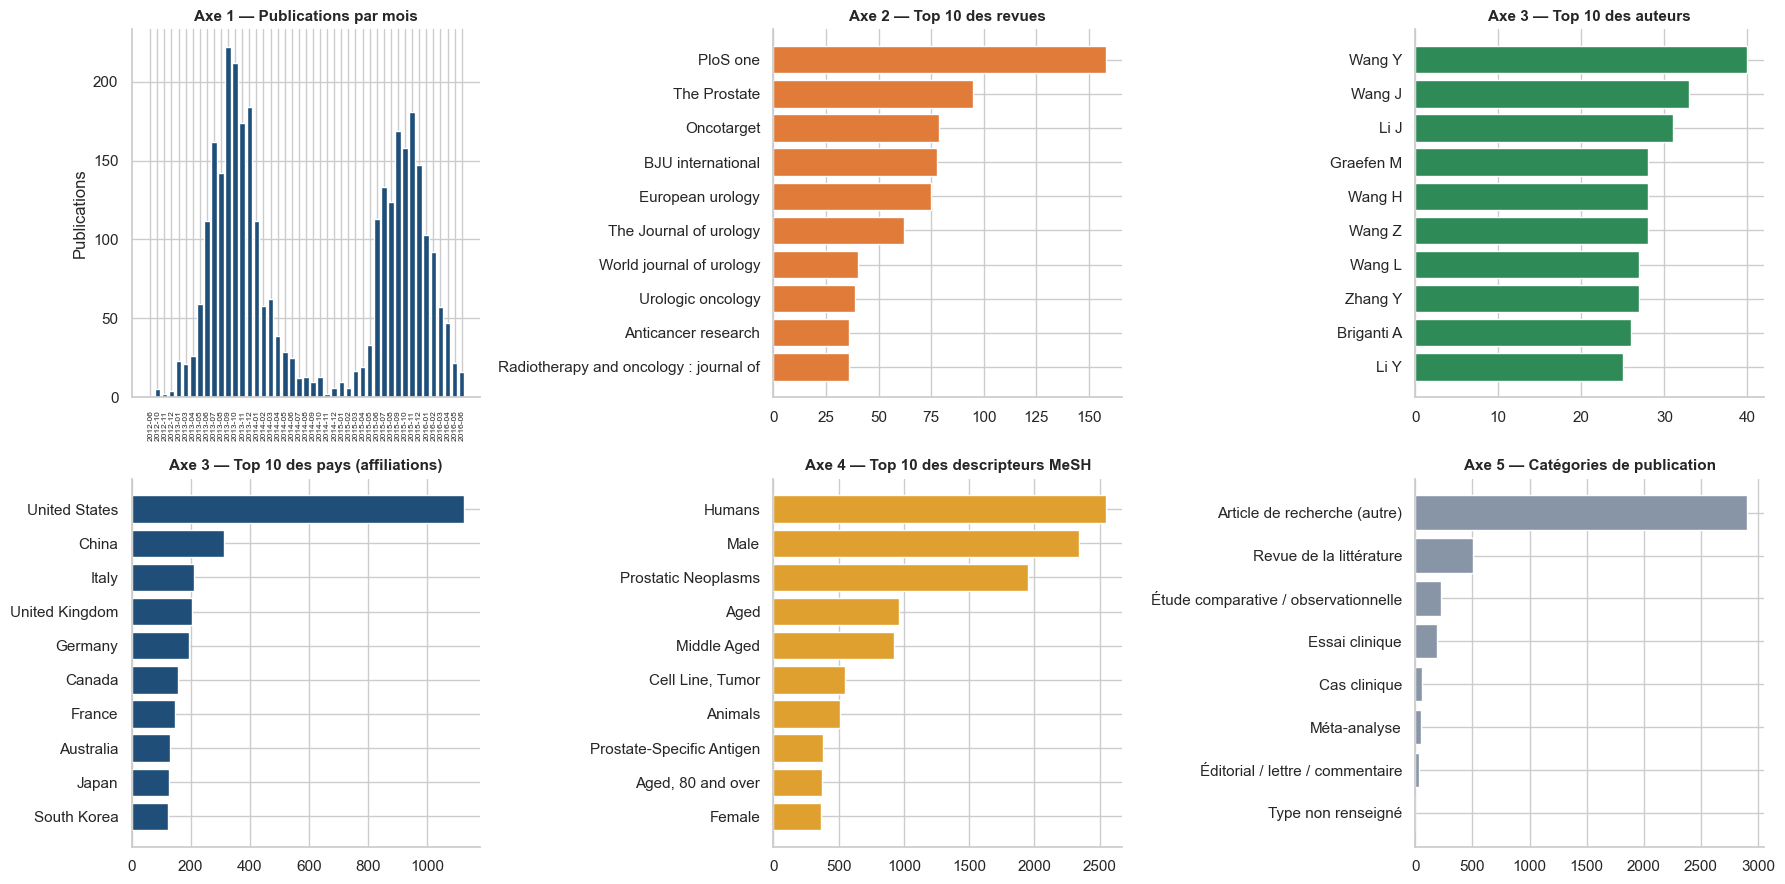

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
m = pd.read_sql("SELECT * FROM v_publications_par_mois ORDER BY annee, mois", con); m["période"] = m.annee.astype(str) + "-" + m.mois.astype(int).astype(str).str.zfill(2)
ax[0, 0].bar(m["période"], m.nb_publications, color=C["main"]); ax[0, 0].set(title="Axe 1 — Publications par mois", ylabel="Publications"); ax[0, 0].tick_params(axis="x", rotation=90, labelsize=6)
r = pd.read_sql("SELECT revue, nb_publications FROM v_publications_par_revue ORDER BY nb_publications DESC LIMIT 10", con).iloc[::-1]; ax[0, 1].barh(r.revue.str[:38], r.nb_publications, color=C["accent"]); ax[0, 1].set(title="Axe 2 — Top 10 des revues")
a = pd.read_sql("SELECT nom || ' ' || COALESCE(initiales, '') AS auteur, nb_publications FROM v_auteurs_publications WHERE type_auteur = 'Individuel' ORDER BY nb_publications DESC LIMIT 10", con).iloc[::-1]; ax[0, 2].barh(a.auteur, a.nb_publications, color=C["ok"]); ax[0, 2].set(title="Axe 3 — Top 10 des auteurs")
p = pd.read_sql("SELECT pays, nb_publications FROM v_publications_par_pays_affiliation WHERE pays <> 'Non renseigné' ORDER BY nb_publications DESC LIMIT 10", con).iloc[::-1]; ax[1, 0].barh(p.pays, p.nb_publications, color=C["main"]); ax[1, 0].set(title="Axe 3 — Top 10 des pays (affiliations)")
t = pd.read_sql("SELECT descripteur, nb_publications FROM v_themes_mesh ORDER BY nb_publications DESC LIMIT 10", con).iloc[::-1]; ax[1, 1].barh(t.descripteur.str[:38], t.nb_publications, color=C["warn"]); ax[1, 1].set(title="Axe 4 — Top 10 des descripteurs MeSH")
c = pd.read_sql("SELECT categorie, nb_publications FROM v_categories_publication ORDER BY nb_publications", con); ax[1, 2].barh(c.categorie, c.nb_publications, color=C["grey"]); ax[1, 2].set(title="Axe 5 — Catégories de publication")
for a_ in ax.ravel(): a_.title.set_fontsize(11)
plt.tight_layout(); plt.show()

In [11]:
display_ = {
 "Axe 3 — collaborations entre institutions (top 5)": "SELECT * FROM v_collaborations_institutions ORDER BY nb_publications_communes DESC LIMIT 5",
 "Axe 3 — collaborations entre pays (top 5)": "SELECT * FROM v_collaborations_pays ORDER BY nb_publications_communes DESC LIMIT 5",
 "Axe 4 — substances chimiques (top 5)": "SELECT substance, registre, nb_publications FROM v_substances ORDER BY nb_publications DESC LIMIT 5",
 "Axe 5 — types de publication (top 5)": "SELECT * FROM v_types_publication ORDER BY nb_publications DESC LIMIT 5"}
for titre, sql in display_.items(): print(f"\n▸ {titre}"); print(pd.read_sql(sql, con).to_string(index=False))


▸ Axe 3 — collaborations entre institutions (top 5)
                         institution_1                                            institution_2  nb_publications_communes
Fred Hutchinson Cancer Research Center                                 University of Washington                        10
          Brigham and Women's Hospital                             Dana-Farber Cancer Institute                         9
                      CHU Henri-Mondor Département d'urologie-andrologie-transplantation rénale                         7
                        Martini-Clinic                     University of Montreal Health Center                         7
                  University of Oxford                                 University of Washington                         6

▸ Axe 3 — collaborations entre pays (top 5)
        pays_1        pays_2  nb_publications_communes
        Canada United States                        48
         Italy United States                        46
Unite

---
# L5 — Visualisation du schéma réalisé
SQLite n'a pas d'interface : la base est un simple fichier. Ce schéma est donc **dessiné à partir de la base chargée** (les tables, clés primaires et clés étrangères sont lues directement dans `dw_pubmed.db`, ce n'est pas un croquis manuel). Il est enregistré dans `load_out/` (`schema_dw.png`, `schema_dw.svg`, version complète et version compacte « clés seulement »).
Pour **explorer la base avec une interface graphique** : *DB Browser for SQLite* (gratuit, tables et requêtes) ou *DBeaver* (gratuit, **diagramme ER** automatique : clic droit sur la base → *View Diagram*).

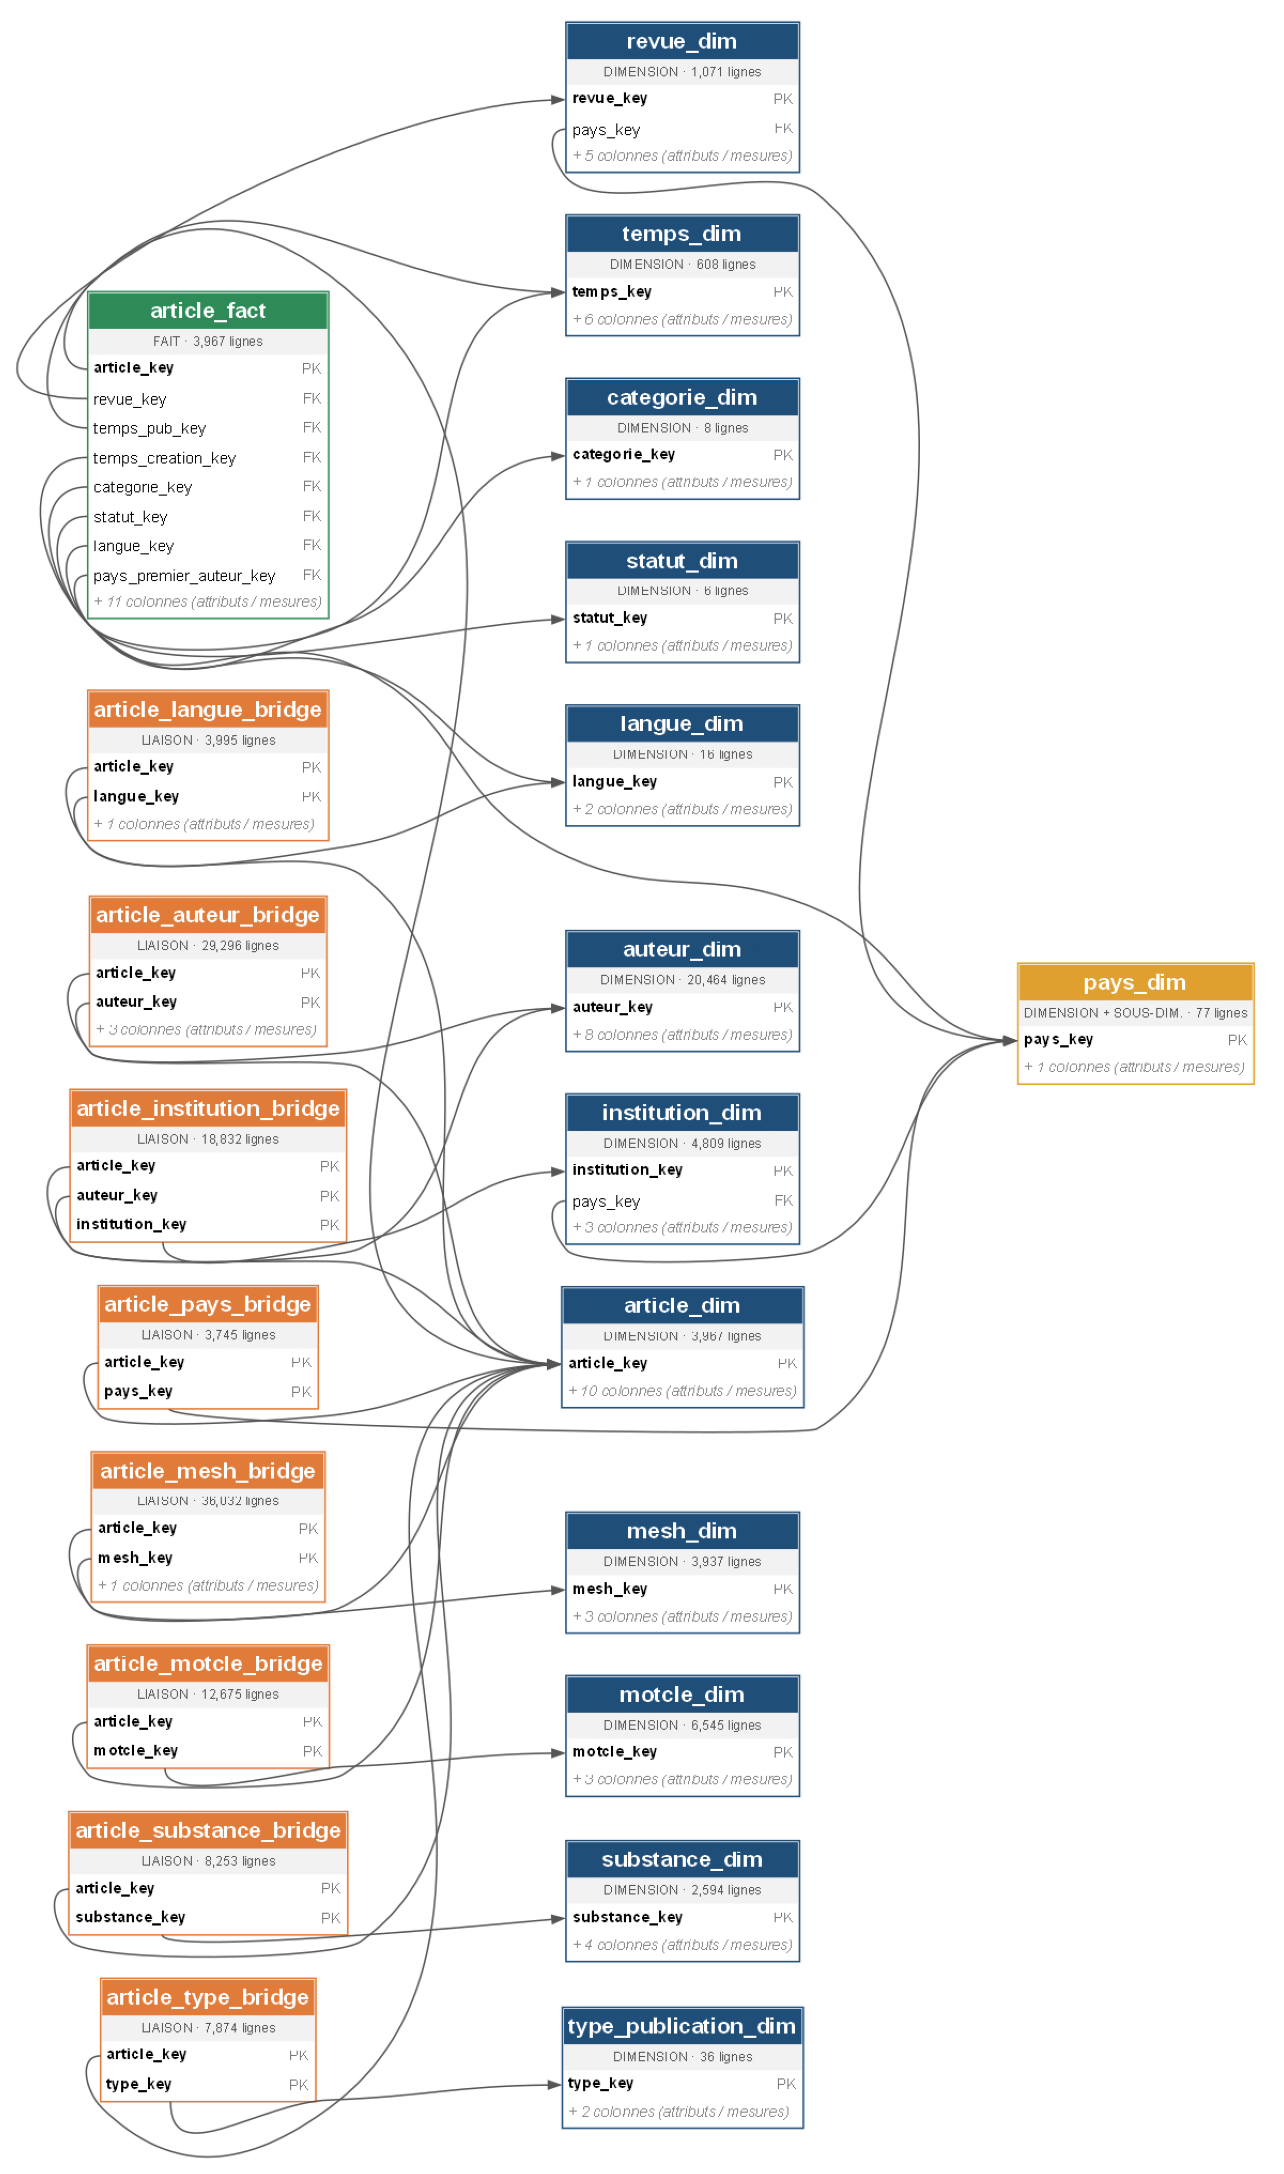

In [12]:
import shutil, subprocess
def schema_dot(db_path, sortie, compact=False):
    """Dessine le schéma physique (tables, PK, FK, volumes) lu dans la base. Écrit un .dot, et .png/.svg si Graphviz (`dot`) est installé."""
    c = sqlite3.connect(db_path)
    tabs = [r[0] for r in c.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' AND name <> 'etl_log' ORDER BY name")]
    nature = lambda t: ("#2E8B57", "FAIT") if t == "article_fact" else ("#E07B39", "LIAISON") if t.endswith("_bridge") else ("#E0A030", "DIMENSION + SOUS-DIM.") if t == "pays_dim" else ("#1F4E79", "DIMENSION")
    L = ["digraph DW {", 'rankdir=LR; splines=true; nodesep=0.25; ranksep=1.6; bgcolor="white"; node [shape=plaintext, fontname="Helvetica"]; edge [color="#555555", arrowsize=0.7];']
    for t in tabs:
        col, lab = nature(t); fks = {r[3] for r in c.execute(f"PRAGMA foreign_key_list({t})")}; rows, autres = [], 0
        for _, nom, ty, nn, _, pk in c.execute(f"PRAGMA table_info({t})"):
            if compact and not pk and nom not in fks: autres += 1; continue
            tag = "PK" if pk else ("FK" if nom in fks else "")
            rows.append(f'<TR><TD ALIGN="LEFT" PORT="{nom}"><FONT POINT-SIZE="10">{"<B>" if pk else ""}{nom}{"</B>" if pk else ""}</FONT></TD><TD ALIGN="RIGHT">{("<FONT POINT-SIZE=\'9\' COLOR=\'#777777\'>" + tag + "</FONT>") if tag else " "}</TD></TR>')
        if autres: rows.append(f'<TR><TD COLSPAN="2" ALIGN="LEFT"><FONT POINT-SIZE="9" COLOR="#888888"><I>+ {autres} colonnes (attributs / mesures)</I></FONT></TD></TR>')
        n = c.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
        L.append(f'"{t}" [label=<<TABLE BORDER="1" CELLBORDER="0" CELLSPACING="0" CELLPADDING="3" COLOR="{col}"><TR><TD COLSPAN="2" BGCOLOR="{col}"><FONT COLOR="white"><B>{t}</B></FONT></TD></TR>'
                 f'<TR><TD COLSPAN="2" BGCOLOR="#F2F2F2"><FONT POINT-SIZE="8" COLOR="#555555">{lab} · {n:,} lignes</FONT></TD></TR>{"".join(rows)}</TABLE>>];')
    for t in tabs:
        for r in c.execute(f"PRAGMA foreign_key_list({t})"): L.append(f'"{t}":"{r[3]}" -> "{r[2]}":"{r[4]}";')
    L.append("}"); c.close(); Path(str(sortie) + ".dot").write_text("\n".join(L), encoding="utf-8")
    if shutil.which("dot"):
        for fmt in ("png", "svg"): subprocess.run(["dot", f"-T{fmt}", "-Gdpi=110", f"{sortie}.dot", "-o", f"{sortie}.{fmt}"], check=True)
        return True
    return False

con = sqlite3.connect(DB); con.execute("PRAGMA foreign_keys = ON")
ok_full = schema_dot(DB, OUT / "schema_dw"); ok_cpt = schema_dot(DB, OUT / "schema_dw_compact", compact=True)
if ok_cpt:
    img = plt.imread(OUT / "schema_dw_compact.png"); fig = plt.figure(figsize=(13, 13 * img.shape[0] / img.shape[1])); plt.imshow(img); plt.axis("off"); plt.tight_layout(); plt.show()
else:
    print("Graphviz (`dot`) n'est pas installé : le fichier schema_dw.dot a été écrit. Ouvre-le sur https://dreampuf.github.io/GraphvizOnline ou installe Graphviz (https://graphviz.org/download).")

---
# L6 — Journal, rapport et clôture

In [13]:
log = pd.read_sql("SELECT * FROM etl_log ORDER BY run_id, rowid", con); log.to_csv(OUT / "etl_log.csv", index=False, encoding="utf-8-sig")
tail = log[log.run_id == log.run_id.iloc[-1]]
size = DB.stat().st_size / 1e6
print(f"Data Warehouse : {DB.name} ({size:.1f} Mo) · {len(ORDRE)} tables · {len(vues)} vues · {tail.lignes_chargees.sum():,} lignes chargées · {len(log.run_id.unique())} exécution(s) journalisée(s)")
print("Fichiers générés :", ", ".join(sorted(p.name for p in OUT.iterdir())))
con.close()
tail.drop(columns=["run_id"]).set_index("table_name")

Data Warehouse : dw_pubmed.db (10.9 Mo) · 22 tables · 15 vues · 168,807 lignes chargées · 2 exécution(s) journalisée(s)
Fichiers générés : etl_log.csv, schema_dw.dot, schema_dw.png, schema_dw.sql, schema_dw.svg, schema_dw_compact.dot, schema_dw_compact.png, schema_dw_compact.svg, vues_analytiques.sql


,lignes_source,lignes_chargees,duree_s,statut,horodatage
table_name,,,,,
pays_dim,77,77,0.004,OK,2026-10-29T23:02:13
statut_dim,6,6,0.003,OK,2026-10-29T23:02:13
categorie_dim,8,8,0.003,OK,2026-10-29T23:02:13
langue_dim,16,16,0.003,OK,2026-10-29T23:02:13
type_publication_dim,36,36,0.004,OK,2026-10-29T23:02:13
mesh_dim,3937,3937,0.034,OK,2026-10-29T23:02:13
motcle_dim,6545,6545,0.123,OK,2026-10-29T23:02:13
substance_dim,2594,2594,0.026,OK,2026-10-29T23:02:13
temps_dim,608,608,0.013,OK,2026-10-29T23:02:13


---
# 🧾 Bilan de l'étape 3
* **Schéma** : 22 tables (1 fait, 13 dimensions/sous-dimension, 8 tables de liaison) + `etl_log` ; clés primaires, clés étrangères **activées**, `UNIQUE` sur les clés métier, `CHECK` sur les domaines, index sur les clés étrangères. Script exporté : `load_out/schema_dw.sql`.
* **Chargement** : transactionnel et idempotent ; ordre imposé par les dépendances ; journal dans `etl_log`.
* **Contrôles** : volumes CSV ↔ base, intégrité référentielle, cohérence de chaque mesure de la fait avec sa table de liaison, absence de double comptage, 2ᵉ chargement sans effet.
* **Vues analytiques** : une par axe du cahier des charges (`load_out/vues_analytiques.sql`), prêtes pour Power BI.

## ➡️ Étape suivante : tableaux de bord et visualisations (BF08)
Connexion de Power BI (ou d'un tableau de bord Python) aux vues `v_*`, rapport final et documentation.